In [48]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pre_processing import pre_process, json_decode


sns.set_palette("hsv_r")

# This affects things like the size of the labels, lines, and other elements of the plot, but not the overall style. 
# The base context is “notebook”, and the other contexts are “paper”, “talk”, and “poster”, which are version of 
# the notebook parameters scaled by .8, 1.3, and 1.6, respectively.
sns.set_context("talk")

%config Inline.figure_format = 'retina'
%matplotlib inline

## Read in Data 

In [49]:
# File paths for each experimental condition (can contain multiple subjects/files) 
file_paths_baseline = [
    "../data/csv_files/10_baseline.csv", 
    "../data/csv_files/11_baseline.csv", 
    "../data/csv_files/12_baseline.csv", 
    "../data/csv_files/13_baseline.csv"
]

file_paths_repulse = [
    "../data/csv_files/10_repulse.csv", 
    "../data/csv_files/11_repulse.csv", 
    "../data/csv_files/12_repulse.csv", 
    "../data/csv_files/13_repulse.csv"
]

file_paths_udl = [
    "../data/csv_files/10_udl.csv", 
    "../data/csv_files/11_udl.csv", 
    "../data/csv_files/12_udl.csv", 
    "../data/csv_files/12_udl.csv"
]

# Subject identifiers corresponding to the datasets
# Actual participants have randomly generated KinArm IDs
subject_list = ["671105437",    
                "972519978", 
                "854984556", 
                "651255439"]    

# Load CSV files & label condition
df_baseline_raw = pre_process(file_paths_baseline, subject_list)
df_baseline_raw['phase'] = 'baseline'

df_repulse_raw = pre_process(file_paths_repulse, subject_list)
df_repulse_raw['phase'] = 'repulse'

df_udl_raw = pre_process(file_paths_udl, subject_list)
df_udl_raw['phase'] = 'udl'

# Combine all conditions into a single dataset
df = pd.concat([df_baseline_raw, df_repulse_raw, df_udl_raw]).reset_index(drop=True)

# Add 5 to each subject ID (the 5 are from pilot data)
df["SN"] = df["SN"].astype(int) + 9

# Reset the trial number column that resets for each subject
df["TN"] = df.groupby("SN").cumcount()
df

,SN,TN,target_angle,probe,feedback,reach_feedback,rt,mt,peak_vel,theta_40,theta_100,theta_pv,theta_end,Subject ID,phase
0,10,0,120,0,0,too early,0.464,NaN,45.810251,17.062466,10.102503,9.367951,2.511211,671105437,baseline
1,10,1,30,0,0,good reach,0.977,0.197,54.162542,3.119648,4.387282,4.553708,5.664619,671105437,baseline
2,10,2,90,0,0,good reach,0.889,0.177,61.096475,16.767686,13.632011,13.527260,10.013021,671105437,baseline
3,10,3,60,0,0,good reach,0.897,0.261,42.529000,2.366674,6.091430,3.324203,-0.981532,671105437,baseline
4,10,4,180,0,0,good reach,0.903,0.205,51.701278,-4.407044,-4.137273,-3.447047,-0.133353,671105437,baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6875,13,1715,30,1,0,good reach,0.506,0.144,78.590818,9.572223,11.733629,11.253306,10.537037,651255439,udl
6876,13,1716,120,0,0,too early,0.492,NaN,65.554097,4.590842,3.946429,3.774350,3.120612,651255439,udl
6877,13,1717,120,0,0,good reach,0.684,0.150,75.958061,4.127166,2.684305,2.133565,1.292137,651255439,udl
6878,13,1718,120,0,0,good reach,0.774,0.171,65.773260,2.685754,1.684434,1.053026,0.568168,651255439,udl


## Define Functions 

In [50]:
# function to unpack repeated target value from series
# WE HAVENT USE THIS ONE YET.. copied from Jeremy's analysis script
def find_rep(group):
    vals = group['Repeated_Target'].iloc[0]
    return vals[1:4]   


def N_finder(group, N_minus_targ):
    
    # Find trials where N-1 had the specified target
    N_trial_num = (group.loc[group['target_angle'] == N_minus_targ,'TN'] + 1)

    # Return trial N
    N_df = group.loc[group['TN'].isin(N_trial_num)]
    return N_df


def calculate_se_index(df, y_col):
    """
    calculate the sequential effect (SE) index per participant 
    POSITIVE SE Index = attractive bias (UDL)
    NEGATIVE SE Index = repulsive bias (REPULSE)

    parameters: 
    df : DataFrame; data to calculate SE index from
    y_col : str; column containing corrected bias

    output: 
    df with the SE index per participant 
    """
    negative_mean = df.loc[df["target_angle_diff"] < 0].groupby("SN")[y_col].mean()
    positive_mean = df.loc[df["target_angle_diff"] > 0].groupby("SN")[y_col].mean()

    return negative_mean - positive_mean 

def circ_dist(ang1, ang2):

    ang1rad = np.deg2rad(ang1)
    ang2rad = np.deg2rad(ang2)
    ang_dist = np.rad2deg(np.arctan2(np.sin(ang1rad), np.cos(ang2rad)))

    return ang_dist


## should probably create a function that determines the repeated target and changes all the targets to be centred around ZERO 

## Data Wrangling 

In [51]:
## Define epochs for each phase of the experiment (trial number ranges for each phase)
epochs = {
    'baseline':(0, 15),                 # Baseline reaching
    'repulse':(16, 715),                # Main experiment block
    'repulse_clean':(116, 715),         # For repulse bias correctinon
    'udl_baseline_FB': (716, 785),      # Baseline reaching 
    'udl_baseline_noFB': (786, 855),    # For UDL bias corrrection  
    'udl_baseline_noFB_second_half': (821, 855),    # For UDL bias corrrection  
    'udl':(856, 1719),                  # Main experiment block
    'udl_full':(716, 1719),                  # including the baseline
}
## change the EPOCHS so its not inclusive?? --> makes it more intuitive?? 


# Central/repeated target angle for each participant
# Update this dictionary as new participants are added
central_target = {
    10: 120,
    11: 60,
    12: 120,
    13: 60
}

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target.items():
    mask = df["SN"] == sn
    TA_rad_shift = df.loc[mask, "target_angle"] - central_angle
    df.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()

# Get target location difference (delta target angle) values
df['target_angle_diff'] = pd.Series(pd.NA, index=df.index, dtype='Float64')
# NOTES:
# 1) CW is negative, CCW is positive 
# 2) add one to starting index because we want the first trial for every block to be NA
mask = (df['TN'] >= epochs['repulse'][0]) & (df['TN'] <= epochs['repulse'][1])
RadTAN1diff_repulse = np.deg2rad(df.loc[mask].groupby('SN')['target_angle'].diff(periods=1))
df.loc[mask,'target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_repulse), np.cos(RadTAN1diff_repulse)))

mask = (df['TN'] >= epochs['udl_full'][0]) & (df['TN'] <= epochs['udl_full'][1])
RadTAN1diff_udl = np.deg2rad(df.loc[mask].groupby('SN')['target_angle'].diff(periods=1))
df.loc[mask,'target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_udl), np.cos(RadTAN1diff_udl)))

# Round 
df['target_angle_diff'] = df['target_angle_diff'].round().astype('Int64')

bias_subset = (
    df.loc[(df['TN'] >= epochs['repulse_clean'][0]) & (df['TN'] < epochs['repulse_clean'][1]) & 
  #  (df['reach_feedback'] == 'good reach') & 
    (df['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_repulse'})
)
df = df.merge(bias_subset, on=['SN', 'target_angle'], how='left')
# Correct for target-level reach biases (for REPULSE) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df['theta_pv'] - df['bias_repulse'])
df['corrected_bias_repulse'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

# Calculate bias for each participant (for UDL), which is used for bias correction in the UDL condition
bias_subset = (
    df.loc[(df['TN'] >= epochs['udl_baseline_noFB'][0]) & (df['TN'] < epochs['udl_baseline_noFB'][1]) & 
    # (df['reach_feedback'] == 'good reach') & 
    (df['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_udl'})
)
df = df.merge(bias_subset, on=['SN', 'target_angle'], how='left')
# Correct for target-level reach biases (for UDL) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df['theta_pv'] - df['bias_udl'])
df['corrected_bias_udl'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

df

,SN,TN,target_angle,probe,feedback,reach_feedback,rt,mt,peak_vel,theta_40,theta_100,theta_pv,theta_end,Subject ID,phase,target_angle_diff,bias_repulse,corrected_bias_repulse,bias_udl,corrected_bias_udl
0,10,0,0,0,0,too early,0.464,NaN,45.810251,17.062466,10.102503,9.367951,2.511211,671105437,baseline,<NA>,9.065194,0.302757,3.291397,6.076554
1,10,1,-90,0,0,good reach,0.977,0.197,54.162542,3.119648,4.387282,4.553708,5.664619,671105437,baseline,<NA>,-3.715832,8.269540,-3.350811,7.904520
2,10,2,-30,0,0,good reach,0.889,0.177,61.096475,16.767686,13.632011,13.527260,10.013021,671105437,baseline,<NA>,6.030888,7.496372,2.939421,10.587840
3,10,3,-60,0,0,good reach,0.897,0.261,42.529000,2.366674,6.091430,3.324203,-0.981532,671105437,baseline,<NA>,-0.628944,3.953148,-2.955364,6.279568
4,10,4,60,0,0,good reach,0.903,0.205,51.701278,-4.407044,-4.137273,-3.447047,-0.133353,671105437,baseline,<NA>,-2.255705,-1.191342,-3.281356,-0.165691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6875,13,1715,-30,1,0,good reach,0.506,0.144,78.590818,9.572223,11.733629,11.253306,10.537037,651255439,udl,-90,-5.366618,16.619924,-1.793345,13.046650
6876,13,1716,60,0,0,too early,0.492,NaN,65.554097,4.590842,3.946429,3.774350,3.120612,651255439,udl,90,12.578721,-8.804372,0.574163,3.200187
6877,13,1717,60,0,0,good reach,0.684,0.150,75.958061,4.127166,2.684305,2.133565,1.292137,651255439,udl,0,12.578721,-10.445156,0.574163,1.559402
6878,13,1718,60,0,0,good reach,0.774,0.171,65.773260,2.685754,1.684434,1.053026,0.568168,651255439,udl,0,12.578721,-11.525696,0.574163,0.478863


# Plot bias across all random phase trials (using theta_pv)

### changed to analysis with repulse_clean

Text(0, 0.5, 'Corrected Bias')

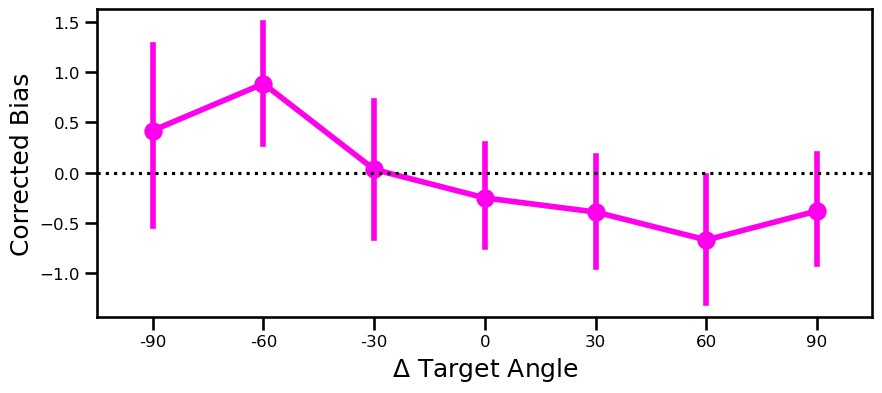

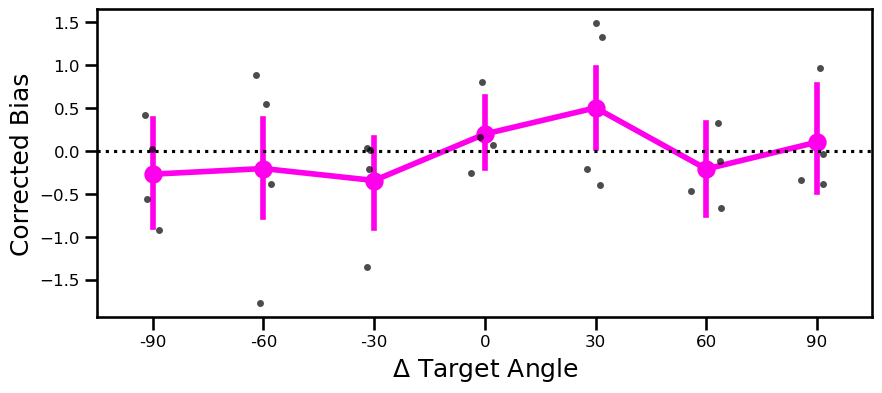

In [52]:
repulse_mask = (
    (df['TN'] >= epochs['repulse_clean'][0]) & (df['TN'] <= epochs['repulse_clean'][1]) & 
    (df['reach_feedback'] == 'good reach') &  
    (df["target_angle_diff"].abs() <= 90) &
    (df['rt'] > 0.5) &  
    (np.abs(df['theta_pv']) < 60)
)

df_repulse = df.loc[repulse_mask].copy()

subject_means_repulse = (
    df_repulse
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse' ]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    # data=df_repulse,
    # to look at a single subject (comment)
    data = df_repulse.loc[df_repulse["SN"] == 10],
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)
ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

fig2, ax2 = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax2
)
sns.stripplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax2
)
ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')


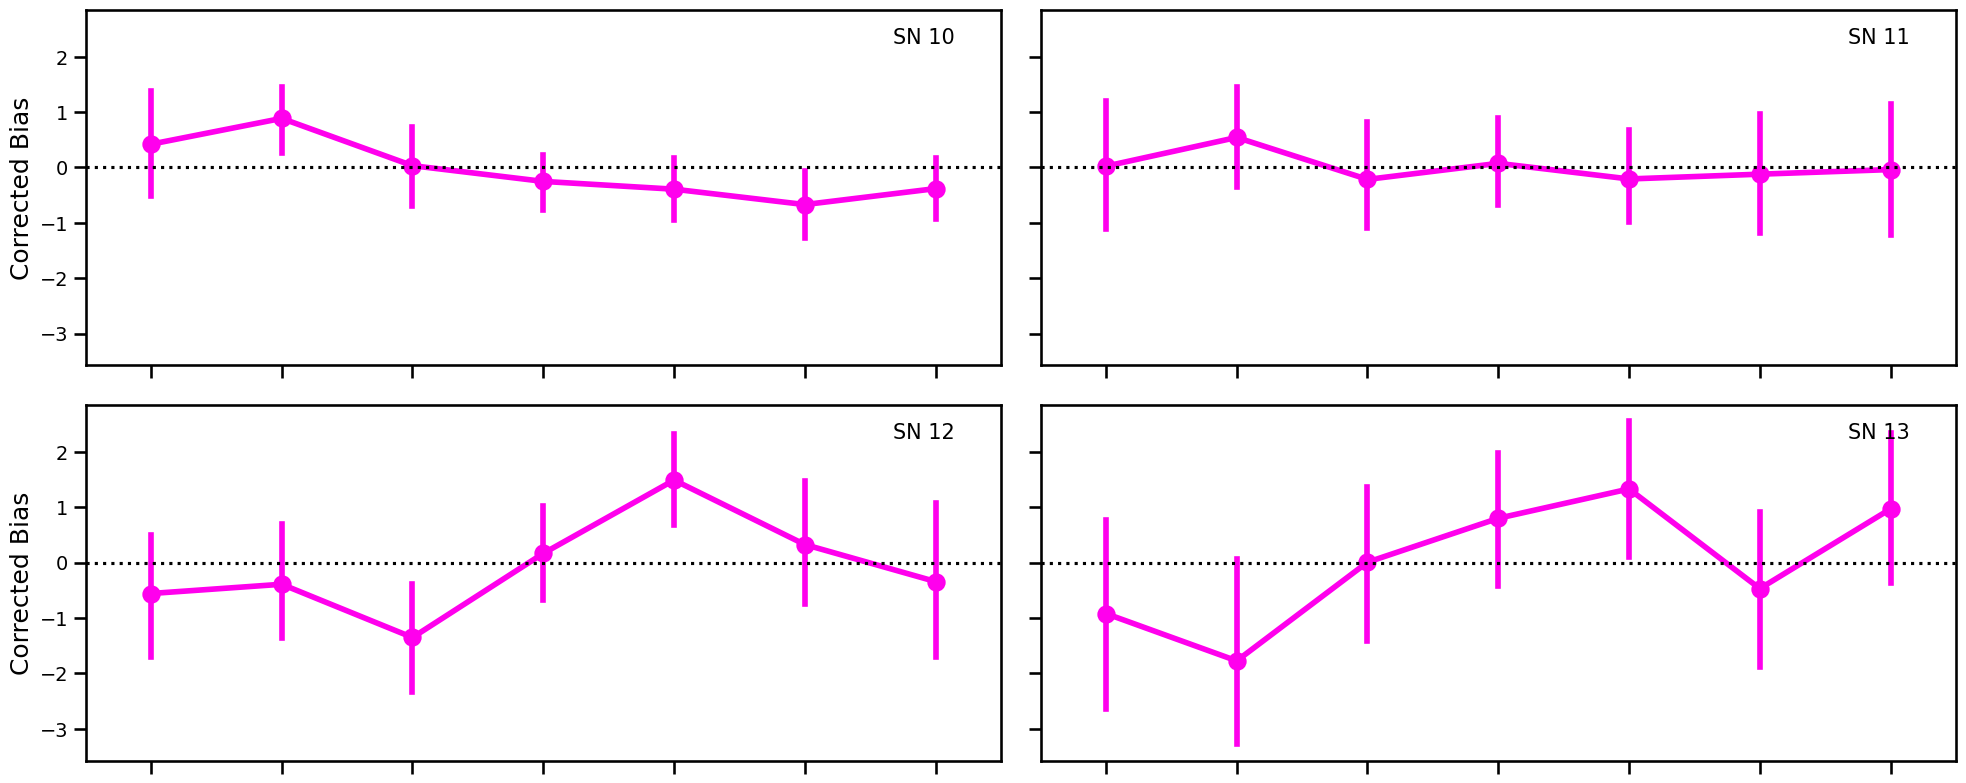

In [53]:
participants = sorted(df_repulse['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_repulse[df_repulse['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_repulse',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

# Plotting biases in use-dependent phase (using theta_pv)

/var/folders/g6/bw3kklz96vl7dn2xz_xpz9440000gn/T/ipykernel_69278/399675501.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(N_finder, N_minus_targ=120)


Text(0, 0.5, 'Corrected Bias')

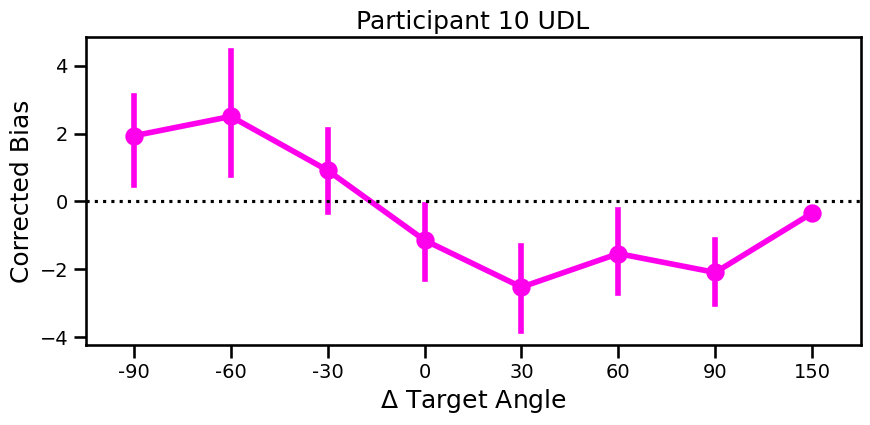

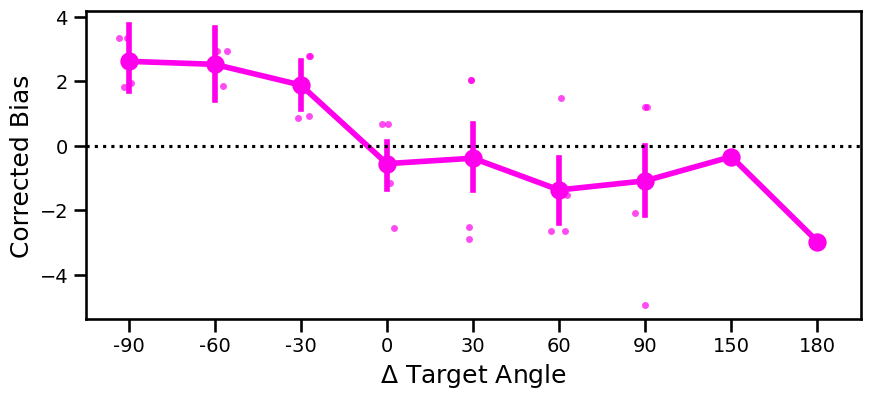

In [56]:
mask_udl = (
    (df['TN'] >= epochs['udl'][0]) & (df['TN'] <= epochs['udl'][1]) & 
    (df['reach_feedback'] == 'good reach') & 
    (df['rt'] > 0.5) &   
    (df['theta_pv'].abs() < 60)
)

df_udl = df.loc[mask_udl].copy()

df_udl_constrained = (
    df_udl
    .groupby('SN', as_index=False)
    .apply(N_finder, N_minus_targ=120)
    .reset_index(drop=True)
).copy()

df_udl_constrained = df_udl.loc[df_udl['probe'] == 1]

subject_means = df_udl_constrained.groupby(['SN', 'target_angle_diff'])['corrected_bias_udl'].mean().reset_index()

# plot graph for one participant
subject_num = 10
fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_udl_constrained[df_udl_constrained['SN']==subject_num],
    x='target_angle_diff',
    y='corrected_bias_udl',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)
ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias') 
plt.title(f'Participant {subject_num} UDL')


# plot graph for group level 
fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_udl_constrained,
    x='target_angle_diff',
    y='corrected_bias_udl',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)

sns.stripplot(
    data=subject_means,
    x='target_angle_diff',
    y='corrected_bias_udl',
    #color='green',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel(r'$\Delta$ Target Angle')
## change the name of the x axis 
plt.ylabel('Corrected Bias') 

# plt.savefig('withFB.png', dpi=600, bbox_inches='tight')

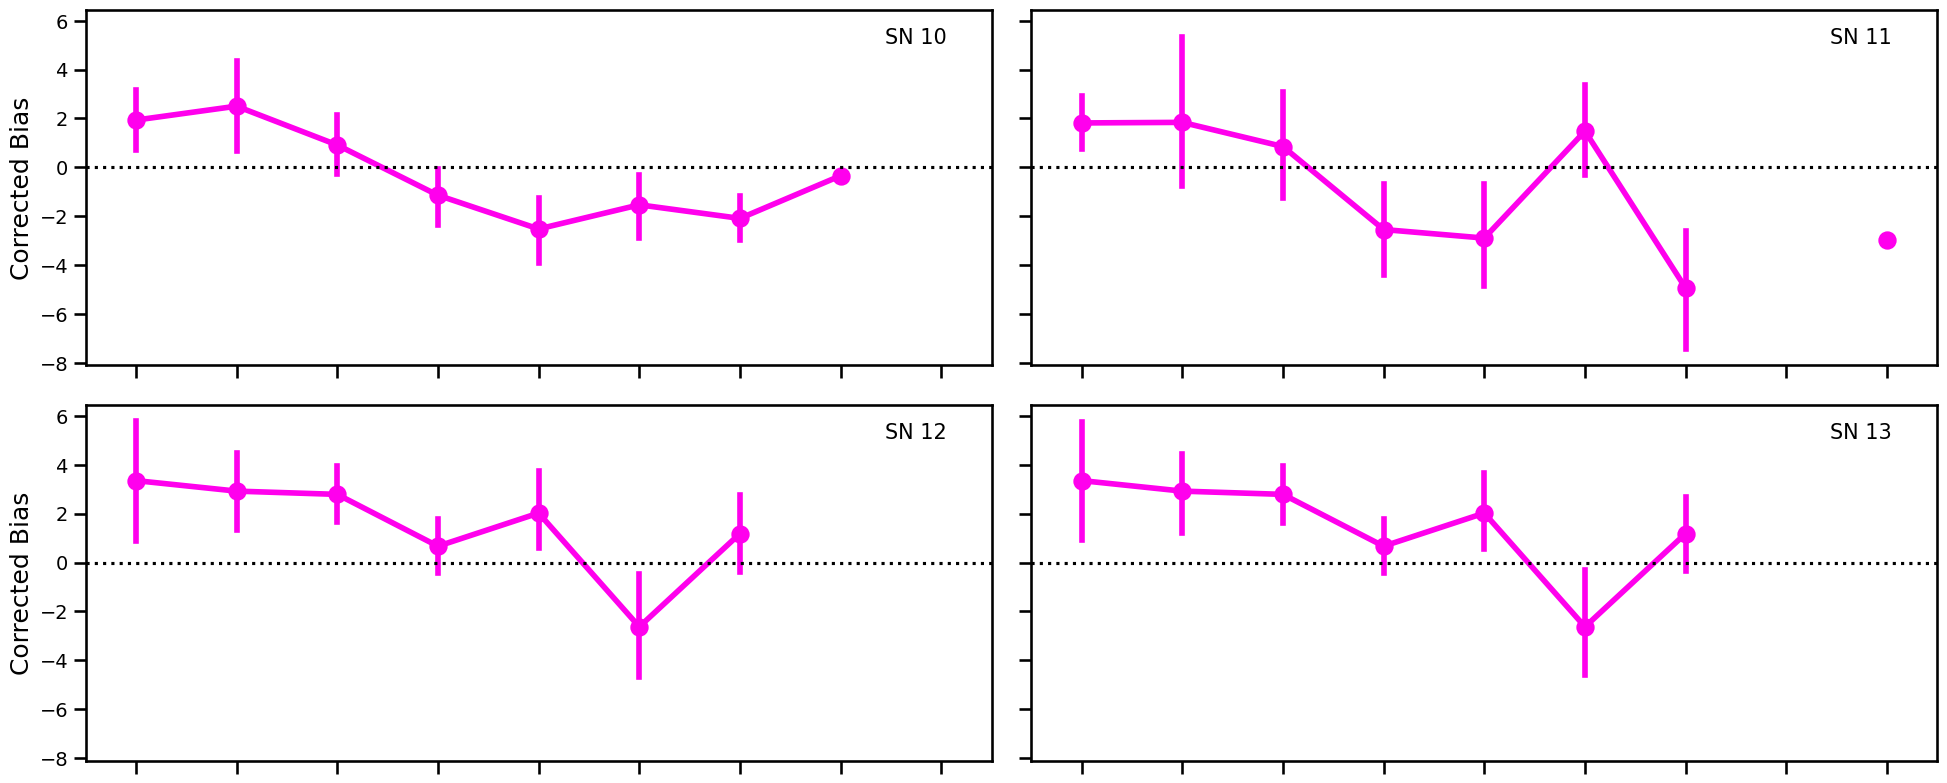

In [55]:
participants = sorted(df_udl_constrained['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_udl_constrained[df_udl_constrained['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_udl',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

pick a participant -- go to data wrangler and look at the differnet columns 